# Problem 1 — Task 1: Data pipelines (5 marks)
Run all cells in order. Only standard-library, NumPy, PyTorch and Matplotlib code is used here.
The missing Individualisation table means seeds `(0, 1, 2)` are provisional model/split seeds.
Adding-data seeds remain fixed by the assignment, independently of model seeds.
AI assistance: Codex implemented and tested this permitted data-pipeline task; include this use in the final AI-use statement. No restricted cells or attention implementations are included.

In [1]:
from pathlib import Path
import random
import urllib.request
import zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path('.') if Path('problem1').is_dir() else Path('..')
DATA = ROOT / 'data'
FIGURES = ROOT / 'problem1' / 'figures'
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)  # Provisional until the missing variants table is supplied.
CHANNELS = ('body_acc_x', 'body_acc_y', 'body_acc_z',
            'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
            'total_acc_x', 'total_acc_y', 'total_acc_z')
ACTIVITIES = ('walking', 'upstairs', 'downstairs', 'sitting', 'standing', 'laying')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [2]:
seed_everything(0)
a = (random.random(), np.random.rand(), torch.rand(1).item())
seed_everything(0)
assert a == (random.random(), np.random.rand(), torch.rand(1).item())
print('PASS: random, NumPy and PyTorch seed reproducibility')

PASS: random, NumPy and PyTorch seed reproducibility


In [3]:
def download_har(data_dir=DATA):
    """Download official archive, handling its optional nested ZIP."""
    destination = data_dir / 'har'
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()] if destination.exists() else []
    if found and (found[0] / 'test' / 'y_test.txt').exists():
        return found[0]
    archive = data_dir / 'har.zip'
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    if not archive.exists():
        temporary = archive.with_suffix('.download')
        urllib.request.urlretrieve(url, temporary)
        temporary.replace(archive)
    def extract(path, target):
        with zipfile.ZipFile(path) as z:
            # Reject archive members that escape the destination.
            for member in z.infolist():
                if not (target / member.filename).resolve().is_relative_to(target.resolve()):
                    raise ValueError('Unsafe ZIP member')
            z.extractall(target)
    extract(archive, destination)
    for nested in destination.rglob('*.zip'):
        extract(nested, nested.parent)
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()]
    if len(found) != 1:
        raise RuntimeError('Expected one UCI HAR Dataset directory')
    return found[0]

In [4]:
HAR_DIR = download_har()
assert (HAR_DIR / 'train' / 'Inertial Signals').is_dir()
assert (HAR_DIR / 'test' / 'subject_test.txt').is_file()
assert download_har() == HAR_DIR
print('PASS: official download, extraction and cached reuse')

PASS: official download, extraction and cached reuse


In [5]:
def load_har_split(root, split):
    if split not in ('train', 'test'):
        raise ValueError('split must be train or test')
    folder = root / split
    # Each channel is (windows, time); stack to (windows, time, channels).
    x = np.stack([np.loadtxt(folder / 'Inertial Signals' / f'{c}_{split}.txt',
                             dtype=np.float32) for c in CHANNELS], axis=-1)
    labels = np.loadtxt(folder / f'y_{split}.txt', dtype=np.int64)
    subjects = np.loadtxt(folder / f'subject_{split}.txt', dtype=np.int64)
    expected = 7352 if split == 'train' else 2947
    assert x.shape == (expected, 128, 9)
    assert labels.shape == subjects.shape == (expected,)
    assert np.array_equal(np.unique(labels), np.arange(1, 7))
    assert np.isfinite(x).all()
    return x, labels - 1, subjects  # CrossEntropyLoss requires labels 0..5.

In [6]:
x_train_raw, y_train_raw, subjects_train = load_har_split(HAR_DIR, 'train')
x_test_raw, y_test, subjects_test = load_har_split(HAR_DIR, 'test')
assert len(np.unique(subjects_train)) == 21
assert len(np.unique(subjects_test)) == 9
assert not set(subjects_train) & set(subjects_test)
for j, channel in enumerate(CHANNELS):
    expected = np.loadtxt(HAR_DIR / 'train' / 'Inertial Signals' / f'{channel}_train.txt', dtype=np.float32)
    np.testing.assert_array_equal(x_train_raw[:, :, j], expected)
assert set(y_train_raw) == set(range(6))
print('PASS: official shapes, channel order, labels, finite values and subject separation')
print('Train:', x_train_raw.shape, 'Test:', x_test_raw.shape)

PASS: official shapes, channel order, labels, finite values and subject separation
Train: (7352, 128, 9) Test: (2947, 128, 9)


In [7]:
def subject_split(subjects, seed):
    train_subjects = np.unique(subjects)
    held_out = np.random.default_rng(seed).choice(train_subjects, 4, replace=False)
    validation = np.isin(subjects, held_out)
    return np.flatnonzero(~validation), np.flatnonzero(validation), held_out

In [8]:
for seed in SEEDS:
    train_idx, val_idx, held_out = subject_split(subjects_train, seed)
    assert len(held_out) == 4
    assert not set(subjects_train[train_idx]) & set(subjects_train[val_idx])
    assert len(np.unique(subjects_train[train_idx])) == 17
    assert np.array_equal(np.sort(np.r_[train_idx, val_idx]), np.arange(7352))
    np.testing.assert_array_equal(held_out, subject_split(subjects_train, seed)[2])
print('PASS: three deterministic, exhaustive, subject-disjoint validation splits')

PASS: three deterministic, exhaustive, subject-disjoint validation splits


In [9]:
def fit_normalizer(training):
    # Pool windows and timesteps, preserving a broadcastable channel axis.
    mean = training.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
    std = training.std(axis=(0, 1), keepdims=True, dtype=np.float64)
    if np.any(std <= 0):
        raise ValueError('Cannot normalize a constant channel')
    return mean, std

def normalize(x, mean, std):
    return ((x - mean) / std).astype(np.float32)

In [10]:
for seed in SEEDS:
    train_idx, val_idx, held_out = subject_split(subjects_train, seed)
    mean, std = fit_normalizer(x_train_raw[train_idx])
    train_x = normalize(x_train_raw[train_idx], mean, std)
    val_x = normalize(x_train_raw[val_idx], mean, std)
    test_x = normalize(x_test_raw, mean, std)
    np.testing.assert_allclose(train_x.mean(axis=(0, 1), dtype=np.float64), 0, atol=1e-6)
    np.testing.assert_allclose(train_x.std(axis=(0, 1), dtype=np.float64), 1, atol=1e-6)
    np.testing.assert_allclose(mean.ravel(), x_train_raw[train_idx].reshape(-1, 9).mean(axis=0, dtype=np.float64))
    # Validation/test use the frozen training transform, never their own statistics.
    np.testing.assert_array_equal(val_x, ((x_train_raw[val_idx] - mean) / std).astype(np.float32))
    np.testing.assert_array_equal(test_x, ((x_test_raw - mean) / std).astype(np.float32))
    assert all(np.isfinite(a).all() for a in (train_x, val_x, test_x))
    assert train_x.dtype == np.float32
    print(f'PASS seed {seed}: held-out subjects {sorted(held_out.tolist())}; windows {len(train_idx)}/{len(val_idx)}/{len(test_x)}; training-only normalization')
try:
    fit_normalizer(np.ones((2, 3, 9)))
except ValueError:
    pass
else:
    raise AssertionError('Constant channels must be rejected')

PASS seed 0: held-out subjects [8, 17, 21, 25]; windows 5886/1466/2947; training-only normalization


PASS seed 1: held-out subjects [15, 16, 25, 29]; windows 5905/1447/2947; training-only normalization


PASS seed 2: held-out subjects [5, 7, 11, 25]; windows 6017/1335/2947; training-only normalization


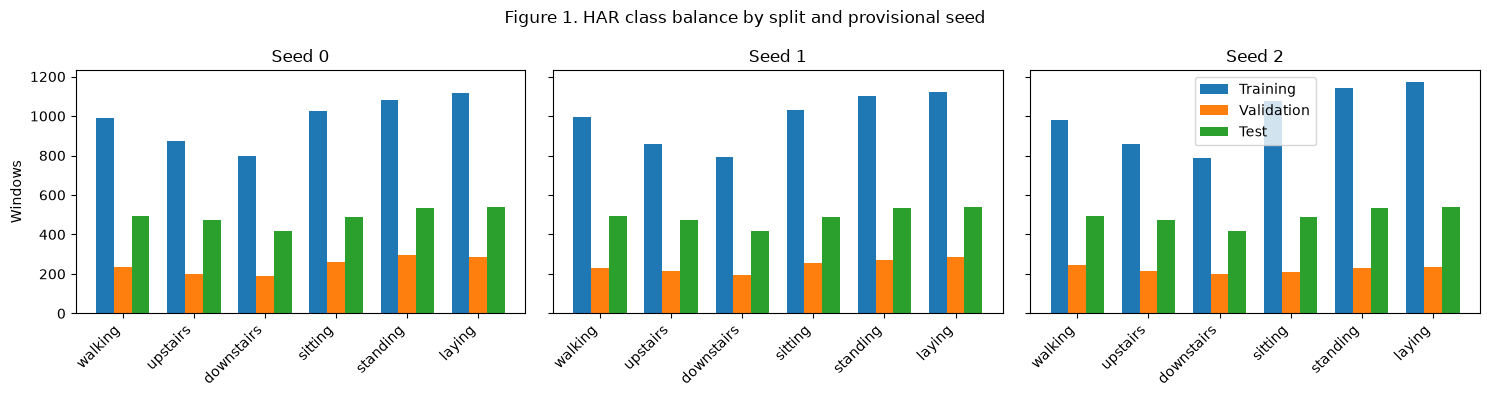

PASS: class-balance figure saved


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, seed in zip(axes, SEEDS):
    train_idx, val_idx, _ = subject_split(subjects_train, seed)
    for offset, labels, label in ((-0.25, y_train_raw[train_idx], 'Training'),
                                  (0, y_train_raw[val_idx], 'Validation'),
                                  (0.25, y_test, 'Test')):
        ax.bar(np.arange(6) + offset, np.bincount(labels, minlength=6), width=0.25, label=label)
    ax.set_xticks(np.arange(6), ACTIVITIES, rotation=45, ha='right')
    ax.set_title(f'Seed {seed}')
axes[0].set_ylabel('Windows')
axes[-1].legend()
fig.suptitle('Figure 1. HAR class balance by split and provisional seed')
fig.tight_layout()
figure_path = FIGURES / 'har_class_balance.png'
fig.savefig(figure_path, dpi=150, bbox_inches='tight')
plt.show()
assert figure_path.stat().st_size > 0
print('PASS: class-balance figure saved')

In [12]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

In [13]:
for T in (50, 100, 200, 400):
    for split, n, seed in (('train', 10000, 0), ('validation', 1000, 1), ('test', 1000, 2)):
        x, y = make_adding(n, T, seed)
        assert x.shape == (n, T, 2) and y.shape == (n,)
        assert x.dtype == y.dtype == np.float32
        markers = x[:, :, 1]
        assert np.isin(markers, [0, 1]).all()
        assert (markers.sum(axis=1) == 2).all()
        assert (markers[:, :T // 2].sum(axis=1) == 1).all()
        assert (markers[:, T // 2:].sum(axis=1) == 1).all()
        assert ((x[:, :, 0] >= 0) & (x[:, :, 0] < 1)).all()
        np.testing.assert_allclose(y, (x[:, :, 0] * markers).sum(axis=1), atol=1e-7, rtol=0)
        if split == 'test':
            print(f'T={T}: constant-1 test baseline MSE={np.mean((y - 1)**2):.6f}')
        del x, y
x1, y1 = make_adding(10, 51, 7)
x2, y2 = make_adding(10, 51, 7)
np.testing.assert_array_equal(x1, x2)
np.testing.assert_array_equal(y1, y2)
assert (x1[:, :25, 1].sum(axis=1) == 1).all()
assert (x1[:, 25:, 1].sum(axis=1) == 1).all()
print('PASS: all 12 required adding datasets, marker positions, targets, dtypes and reproducibility')

T=50: constant-1 test baseline MSE=0.175392
T=100: constant-1 test baseline MSE=0.169709
T=200: constant-1 test baseline MSE=0.167942
T=400: constant-1 test baseline MSE=0.152720
PASS: all 12 required adding datasets, marker positions, targets, dtypes and reproducibility


Task 1 ends here. No training experiments have been run, so `results.csv` contains only its required header. Final student-specific splits must be rerun when the variants table becomes available.

# Problem 1 — Task 2: Cells from scratch (10 marks)
**Status: In Progress — student implementations pending.** AI prepared interfaces, explanations and tests only. You must write each constructor's parameters/initialization and its forward computation yourself. Do not call library recurrent layers, cell classes or fused recurrent operators from the custom cells.

Run All currently reports `PENDING`, not verification success, for the three unfinished cells. After implementing a cell, rerun its definition and adjacent verification cell. Any numerical or shape failure propagates as an assertion error. The strict final check is available once all three are ready.

## Parameter contract and equation references
Use the installed PyTorch `torch.nn.RNN.__doc__`, `torch.nn.LSTM.__doc__`, and `torch.nn.GRU.__doc__` mathematical definitions as references (reviewed for this environment). Reference layers appear only in verification code. Custom classes inherit `torch.nn.Module` and expose these **trainable parameters**, without child layers:

| Attribute | Shape | Meaning |
|---|---|---|
| `weight_ih` | `(g*h, d)` | Stacked input weights |
| `weight_hh` | `(g*h, h)` | Stacked recurrent weights |
| `bias_ih` | `(g*h,)` | Input biases |
| `bias_hh` | `(g*h,)` | Recurrent biases |

Here `g=1,4,3` for RNN/LSTM/GRU. Initialize parameters yourself with finite values, for example uniformly within ±1/√h; verification replaces them with reference weights. A cell takes one time step, not a full sequence. It requires an explicit state. Preserve input dtype/device and autograd.

### Parameter derivation (weights and biases only, no classifier)
Each gate has `h*d` input weights and `h*h` recurrent weights. With one bias its count is `h*d + h*h + h = h(d+h+1)`; multiply by gate count `g`. PyTorch stores **two** length-h bias vectors per gate, giving `g*h(d+h+2)`.

For d=9, h=64: input weights = 576, recurrent weights = 4096, one bias = 64. Thus one gate has 4736 parameters with one bias, or 4800 with two.

| Cell | g | Single-bias derivation | Two-bias PyTorch/custom contract |
|---|---:|---:|---:|
| RNN | 1 | 4736 | 4800 |
| LSTM | 4 | 18944 | 19200 |
| GRU | 3 | 14208 | 14400 |

The extra `g*h` accounts for the difference. RNN and LSTM biases can be summed for their forward equations. **GRU caveat:** the candidate recurrent bias is inside the reset multiplication in PyTorch; a generic single-bias GRU cannot simply absorb it into the input bias. Here the single-bias number is an architectural counting convention; the custom interface retains both biases for exact arbitrary-weight equivalence.


In [2]:
# Verification infrastructure only; no custom cell mathematics.
from torch import nn

CELL_RESULTS = {}  # Recreated on Run All; no stale success flags.
REFERENCE_CLASSES = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}
GATE_COUNTS = {'RNN': 1, 'LSTM': 4, 'GRU': 3}

def parameter_counts(d, h, gates):
    return gates * h * (d + h + 1), gates * h * (d + h + 2)

In [3]:
for kind, expected in {'RNN': (4736, 4800), 'LSTM': (18944, 19200), 'GRU': (14208, 14400)}.items():
    counts = parameter_counts(9, 64, GATE_COUNTS[kind])
    assert counts == expected
    reference = REFERENCE_CLASSES[kind](9, 64, batch_first=True)
    actual = sum(p.numel() for p in reference.parameters())
    assert actual == counts[1]
    print(f'{kind}: single-bias formula={counts[0]}, two-bias formula={counts[1]}, actual PyTorch={actual}; custom count PENDING')

RNN: single-bias formula=4736, two-bias formula=4800, actual PyTorch=4800; custom count PENDING
LSTM: single-bias formula=18944, two-bias formula=19200, actual PyTorch=19200; custom count PENDING
GRU: single-bias formula=14208, two-bias formula=14400, actual PyTorch=14400; custom count PENDING


In [4]:
def copy_reference_weights(custom, reference, kind, d, h):
    """Verification-only copy from a one-layer unidirectional reference."""
    g = GATE_COUNTS[kind]
    shapes = {'weight_ih': (g*h, d), 'weight_hh': (g*h, h),
              'bias_ih': (g*h,), 'bias_hh': (g*h,)}
    assert not list(custom.children()), 'Custom cells must use direct tensor parameters, no child layers'
    actual = dict(custom.named_parameters())
    assert set(actual) == set(shapes), f'Expected trainable parameters {tuple(shapes)}, got {tuple(actual)}'
    with torch.no_grad():
        for name, shape in shapes.items():
            assert actual[name].requires_grad
            assert tuple(actual[name].shape) == shape
            source = getattr(reference, name + '_l0')
            actual[name].copy_(source)
            assert torch.equal(actual[name], source), f'Weight copy failed: {name}'
    assert sum(p.numel() for p in custom.parameters()) == parameter_counts(d, h, g)[1]

In [5]:
# Test copying independently of any custom implementation.
probe = nn.Module()
ref_probe = nn.GRU(9, 64, batch_first=True)
for name, param in ref_probe.named_parameters():
    probe.register_parameter(name.removesuffix('_l0'), nn.Parameter(torch.zeros_like(param)))
copy_reference_weights(probe, ref_probe, 'GRU', 9, 64)
assert all(torch.equal(p, getattr(ref_probe, name + '_l0')) for name, p in probe.named_parameters())
print('PASS: verification weight-copy helper (not a custom-cell verification)')

PASS: verification weight-copy helper (not a custom-cell verification)


In [6]:
def assert_tensor_match(actual, expected, label):
    assert isinstance(actual, torch.Tensor), f'{label}: expected Tensor'
    assert actual.shape == expected.shape, f'{label}: {actual.shape} != {expected.shape}'
    assert actual.dtype == expected.dtype and actual.device == expected.device
    assert torch.isfinite(actual).all(), f'{label}: nonfinite output'
    error = (actual - expected).abs().max().item()
    assert error < 1e-5, f'{label}: max absolute error {error:.8g} must be < 1e-5'
    return error

In [7]:
assert assert_tensor_match(torch.zeros(2, 3), torch.zeros(2, 3), 'equal') == 0
for bad in (torch.zeros(3, 2), torch.ones(2, 3), torch.full((2, 3), float('nan'))):
    try:
        assert_tensor_match(bad, torch.zeros(2, 3), 'deliberate negative test')
    except AssertionError:
        pass
    else:
        raise AssertionError('Comparator accepted a deliberately invalid output')
print('PASS: comparison helper accepts equality and rejects shape/value/NaN errors')

PASS: comparison helper accepts equality and rejects shape/value/NaN errors


In [8]:
def verify_cell(cell_class, kind):
    """Strict verification: unfinished implementations raise NotImplementedError.

    Uses random nonzero states/biases, single and multiple timesteps, two seeds,
    float32/float64 and different batch/input/hidden sizes. Reference calls only.
    """
    worst = 0.0
    cases = 0
    with torch.random.fork_rng(devices=[]):
        for dtype in (torch.float32, torch.float64):
            for seed in (13, 29):
                for batch, steps, d, h in ((1, 1, 3, 5), (4, 7, 9, 64)):
                    torch.manual_seed(seed)
                    reference = REFERENCE_CLASSES[kind](d, h, batch_first=True).to(dtype=dtype)
                    custom = cell_class(d, h).to(dtype=dtype)
                    copy_reference_weights(custom, reference, kind, d, h)
                    x = torch.randn(batch, steps, d, dtype=dtype)
                    h0 = torch.randn(batch, h, dtype=dtype)
                    c0 = torch.randn(batch, h, dtype=dtype)
                    initial = (h0.unsqueeze(0), c0.unsqueeze(0)) if kind == 'LSTM' else h0.unsqueeze(0)
                    with torch.no_grad():
                        expected, final = reference(x, initial)
                        state = (h0.clone(), c0.clone()) if kind == 'LSTM' else h0.clone()
                        reference_state = initial
                        outputs = []
                        for t in range(steps):
                            state = custom(x[:, t, :], state)
                            _, reference_state = reference(x[:, t:t+1, :], reference_state)
                            if kind == 'LSTM':
                                assert isinstance(state, tuple) and len(state) == 2, 'LSTM must return (h_next, c_next)'
                                ht, ct = state
                                worst = max(worst, assert_tensor_match(ct, reference_state[1][0], 'cell state'))
                            else:
                                ht = state
                            worst = max(worst, assert_tensor_match(ht, expected[:, t, :], 'hidden state'))
                            outputs.append(ht)
                        worst = max(worst, assert_tensor_match(torch.stack(outputs, dim=1), expected, 'sequence'))
                        final_h = final[0][0] if kind == 'LSTM' else final[0]
                        worst = max(worst, assert_tensor_match(outputs[-1], final_h, 'final hidden'))
                    cases += 1
    return {'status': 'Completed', 'cases': cases, 'max_abs_diff': worst,
            'custom_params_d9_h64': sum(p.numel() for p in cell_class(9, 64).parameters())}


def report_cell_verification(cell_class, kind):
    # Clear stale success before attempting verification; catch only explicit TODOs.
    CELL_RESULTS[kind] = {'status': 'In Progress'}
    try:
        result = verify_cell(cell_class, kind)
    except NotImplementedError as exc:
        CELL_RESULTS[kind] = {'status': 'Blocked', 'reason': str(exc)}
        print(f'PENDING {kind}: student implementation required. {exc}')
        return
    CELL_RESULTS[kind] = result
    print(f'PASS {kind}: {result}')

In [9]:
class _UnfinishedProbe(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        raise NotImplementedError('harness negative-control placeholder')

try:
    verify_cell(_UnfinishedProbe, 'RNN')
except NotImplementedError:
    print('PASS: strict verifier rejects an unfinished implementation')
else:
    raise AssertionError('Unfinished cell was accepted')

PASS: strict verifier rejects an unfinished implementation


## MyRNNCell — student implementation

For your first implementation, use the tanh Elman equation: $h_t=\tanh(x_tW_{ih}^{T}+b_{ih}+h_{t-1}W_{hh}^{T}+b_{hh})$. The two projected terms must both have shape `(batch,h)`. You must translate this equation into tensor operations yourself.

In [10]:
class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # TODO (student): register and initialize the four trainable parameters.
        # g=1: weight_ih (g*h,d), weight_hh (g*h,h), biases (g*h,).
        raise NotImplementedError('MyRNNCell parameter setup is not implemented')

    def forward(self, x, h_prev):
        # x: (batch,d); h_prev: (batch,h).
        # Return h_next: (batch,h) using your own tensor equations.
        # TODO (student): implement the cell computation; do not call library cells.
        raise NotImplementedError('MyRNNCell forward is not implemented')

In [11]:
report_cell_verification(MyRNNCell, 'RNN')

PENDING RNN: student implementation required. MyRNNCell parameter setup is not implemented


## MyLSTMCell — student implementation

Use packed gate order **input, forget, candidate, output** (`i,f,g,o`). The three control gates use sigmoid and the candidate uses tanh. Combine the retained old cell state and gated candidate to obtain the new cell state; gate its tanh to obtain the new hidden state. See the equations in `torch.nn.LSTM.__doc__`. Return `(h_next, c_next)`, each `(batch,h)`; do not swap their order.

In [12]:
class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # TODO (student): register and initialize the four trainable parameters.
        # g=4: weight_ih (g*h,d), weight_hh (g*h,h), biases (g*h,).
        raise NotImplementedError('MyLSTMCell parameter setup is not implemented')

    def forward(self, x, state):
        # x: (batch,d); state: (h_prev,c_prev), each (batch,h).
        # Return (h_next,c_next), each (batch,h) using your own tensor equations.
        # TODO (student): implement the cell computation; do not call library cells.
        raise NotImplementedError('MyLSTMCell forward is not implemented')

In [13]:
report_cell_verification(MyLSTMCell, 'LSTM')

PENDING LSTM: student implementation required. MyLSTMCell parameter setup is not implemented


## MyGRUCell — student implementation

Use packed gate order **reset, update, new** (`r,z,n`). PyTorch applies reset **after** the recurrent candidate projection and includes the recurrent candidate bias inside that reset multiplication. It does not project a reset-multiplied hidden state. The update gate weights the old hidden state; its complement weights the candidate. See `torch.nn.GRU.__doc__`. Keep input and recurrent candidate biases separate.

In [14]:
class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # TODO (student): register and initialize the four trainable parameters.
        # g=3: weight_ih (g*h,d), weight_hh (g*h,h), biases (g*h,).
        raise NotImplementedError('MyGRUCell parameter setup is not implemented')

    def forward(self, x, h_prev):
        # x: (batch,d); h_prev: (batch,h).
        # Return h_next: (batch,h) using your own tensor equations.
        # TODO (student): implement the cell computation; do not call library cells.
        raise NotImplementedError('MyGRUCell forward is not implemented')

In [15]:
report_cell_verification(MyGRUCell, 'GRU')

PENDING GRU: student implementation required. MyGRUCell parameter setup is not implemented


## Task 2 completion check
The normal summary allows Task 1 to keep running while the student code is unfinished. **A successful notebook run is not Task 2 completion.** Once all cells are implemented, run `require_task2_complete()` explicitly; it re-verifies every class, rather than trusting stored results. The progress tracker must then be updated after reviewing the student code and the saved evidence.

In [16]:
def require_task2_complete():
    verified = {}
    for kind, cls in (('RNN', MyRNNCell), ('LSTM', MyLSTMCell), ('GRU', MyGRUCell)):
        verified[kind] = verify_cell(cls, kind)
        assert verified[kind]['custom_params_d9_h64'] == parameter_counts(9, 64, GATE_COUNTS[kind])[1]
    return verified

print('Task 2 verification summary:', CELL_RESULTS)
if all(CELL_RESULTS.get(k, {}).get('status') == 'Completed' for k in GATE_COUNTS):
    print('All three verification suites passed; student authorship and documentation review still required.')
else:
    print('TASK 2 INCOMPLETE: no custom-cell equivalence or custom parameter-count success is claimed.')

Task 2 verification summary: {'RNN': {'status': 'Blocked', 'reason': 'MyRNNCell parameter setup is not implemented'}, 'LSTM': {'status': 'Blocked', 'reason': 'MyLSTMCell parameter setup is not implemented'}, 'GRU': {'status': 'Blocked', 'reason': 'MyGRUCell parameter setup is not implemented'}}
TASK 2 INCOMPLETE: no custom-cell equivalence or custom parameter-count success is claimed.


## Constructor diagnostics — independent of forward
These checks let us review a student constructor before forward is implemented. They check parameter registration, shape, finite initialization, device/dtype conversion, parameter count, and seeded reproducibility. Finite reproducible values do not prove a particular initialization distribution; inspect the student's initialization code too. The existing strict equivalence verifier still determines numerical success.

In [17]:
def verify_constructor(cell_class, kind):
    shapes = {'weight_ih': (GATE_COUNTS[kind]*64, 9),
              'weight_hh': (GATE_COUNTS[kind]*64, 64),
              'bias_ih': (GATE_COUNTS[kind]*64,),
              'bias_hh': (GATE_COUNTS[kind]*64,)}
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(101)
        cell = cell_class(9, 64)
        params = dict(cell.named_parameters())
        assert set(params) == set(shapes), 'Missing, extra or unregistered parameters'
        assert not list(cell.children()), 'Use direct parameters rather than child layers'
        for name, shape in shapes.items():
            assert params[name].shape == shape, name
            assert params[name].requires_grad, name
            assert torch.isfinite(params[name]).all(), name
        count = sum(p.numel() for p in params.values())
        assert count == parameter_counts(9, 64, GATE_COUNTS[kind])[1]
        torch.manual_seed(101)
        repeated = cell_class(9, 64)
        for name, parameter in repeated.named_parameters():
            assert torch.equal(params[name], parameter), 'Initialization is not seed-reproducible'
        converted = cell.to(dtype=torch.float64)
        assert all(p.dtype == torch.float64 for p in converted.parameters())
    return {'params': count, 'finite': True, 'reproducible': True}


In [18]:
# This diagnostic never marks a cell's forward computation complete.
for kind, cls in (('RNN', MyRNNCell), ('LSTM', MyLSTMCell), ('GRU', MyGRUCell)):
    try:
        details = verify_constructor(cls, kind)
    except NotImplementedError:
        print(f'PENDING {kind} constructor: student parameter initialization required')
    else:
        print(f'PASS {kind} constructor only: {details}')


PENDING RNN constructor: student parameter initialization required
PENDING LSTM constructor: student parameter initialization required
PENDING GRU constructor: student parameter initialization required
